# Customer Churn: Decision Tree and Ensemble Models

**Ensemble methods on a real retention problem**

A single tree model is easy to read but fragile: grown deep it **memorises** the training data and
then swings wildly on data it hasn't seen. This notebook fixes that by combining many trees into an
**ensemble**.

We use the *Telco Customer Churn* dataset (7,043 customers). About **27%** churn, so accuracy alone
is misleading a model that predicts *"nobody leaves"* is already 73% accurate and worthless. As
in earlier weeks we judge everything on **F1 and recall for the "Churn" class**, measured on **both
the training and test sets** so the train/test *gap* the fingerprint of overfitting is always
in view.

| Step | What we do | Why |
|---|---|---|
| **1. Explore** | Exploratory Data Analysis | Understand the data before modelling |
| **2. Preprocess** | Encode **all** features, stratified split | Do transformations as per observations in EDA |
| **3. Baseline** | A single Decision Tree | See high variance / overfitting first-hand |
| **4. Bagging** | `BaggingClassifier`, `RandomForest` | Reduce **variance** by averaging many trees |

---

## Setup: Imports



In [19]:
import warnings
warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import (
    BaggingClassifier,
    RandomForestClassifier
)
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay,
)



RANDOM_STATE = 42

## 1: Load & Explore the Data



In [20]:
url = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"

df = pd.read_csv(url)

In [21]:
df.shape

(7043, 21)

In [22]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [24]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

### why accuracy will mislead us?



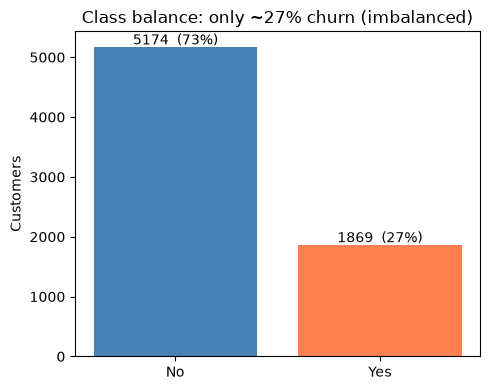

In [25]:
fig, ax = plt.subplots(figsize=(5, 4))
counts = df["Churn"].value_counts()

ax.bar(counts.index, counts.values, color=["steelblue", "coral"])
for i, v in enumerate(counts.values):
    ax.text(i, v + 40, f"{v}  ({v/len(df):.0%})", ha="center")
ax.set_ylabel("Customers")
ax.set_title("Class balance: only ~27% churn (imbalanced)")
plt.tight_layout()
plt.show()

In [26]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce").fillna(0.0)

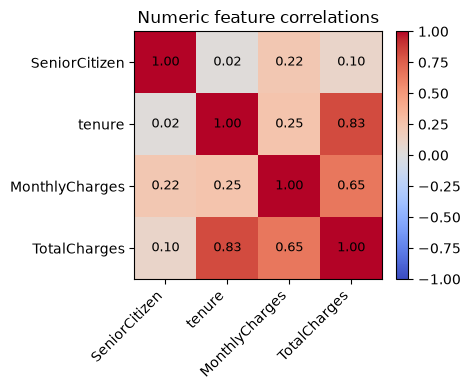

In [27]:

num_cols = df.select_dtypes(include=['number']).columns
corr = df[num_cols].corr()

fig, ax = plt.subplots(figsize=(5, 4))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(num_cols))); ax.set_xticklabels(num_cols, rotation=45, ha="right")
ax.set_yticks(range(len(num_cols))); ax.set_yticklabels(num_cols)
for i in range(len(num_cols)):
    for j in range(len(num_cols)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=9)
fig.colorbar(im, fraction=0.046, pad=0.04)
ax.set_title("Numeric feature correlations")
plt.tight_layout()
plt.show()

## 2: Preprocessing

In [9]:
y = (df["Churn"] == "Yes").astype(int)

# Remove the target column and customer ID from the features
X = df.drop(columns=["Churn", "customerID"])

In [10]:
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    stratify=y,                 # Keep the same class distribution
    random_state=RANDOM_STATE
)

In [11]:
# Numerical columns
numeric_columns = (
    X_train_raw
    .select_dtypes(include="number")
    .columns
    .tolist()
)

# Everything else is categorical
categorical_columns = (
    X_train_raw
    .select_dtypes(exclude="number")
    .columns
    .tolist()
)


In [12]:
encoder = OneHotEncoder(
    handle_unknown="ignore",    # Ignore categories seen only in the test set
    sparse_output=False          # Return a NumPy array instead of a sparse matrix
)


# Learn the categories from training data
encoder.fit(X_train_raw[categorical_columns])




def encode_features(data):

    # Convert categorical columns into one-hot encoded columns
    encoded_array = encoder.transform(
        data[categorical_columns]
    )

    # Convert NumPy array to DataFrame
    encoded_df = pd.DataFrame(
        encoded_array,
        columns=encoder.get_feature_names_out(categorical_columns),
        index=data.index
    )

    # Keep the numerical columns
    numeric_df = data[numeric_columns]

    # Combine numerical and encoded categorical columns
    final_df = pd.concat(
        [numeric_df, encoded_df],
        axis=1
    )

    return final_df



X_train = encode_features(X_train_raw)
X_test = encode_features(X_test_raw)


feature_names = X_train.columns

print(f"Total features after encoding : {X_train.shape[1]}")

print(f"Training samples : {X_train.shape[0]}")
print(f"Testing samples  : {X_test.shape[0]}")

print(f"Training churn rate : {y_train.mean():.3f}")
print(f"Testing churn rate  : {y_test.mean():.3f}")

Total features after encoding : 45
Training samples : 5634
Testing samples  : 1409
Training churn rate : 0.265
Testing churn rate  : 0.265


### Evaluation Helper

This helper does one job:
print the "Churn" class metrics for **train and test side by side** (so the overfitting gap is
obvious).

In [13]:
results = {}   # filled as we go

def evaluate(name, model):
    """Print train vs test metrics for the 'Churn' class and store the scores.
    The model must already be fitted (we fit it in its own cell)."""
    yhat_tr, yhat_te = model.predict(X_train), model.predict(X_test)

    def block(yt, yp):
        return (accuracy_score(yt, yp), precision_score(yt, yp),
                recall_score(yt, yp), f1_score(yt, yp,))

    tr, te = block(y_train, yhat_tr), block(y_test, yhat_te)

    print(f"  {name}")
    print(f"  {'metric':<12}{'train':>8}{'test':>8}")
    for lbl, i in [("Accuracy", 0), ("Precision", 1), ("Recall", 2), ("F1 (Churn)", 3)]:
        print(f"  {lbl:<12}{tr[i]:>8.3f}{te[i]:>8.3f}")
    print(f"  {'F1 gap':<12}{'':>8}{tr[3] - te[3]:>8.3f}")

    results[name] = {"model": model, "y_pred_test": yhat_te,
                     "train_f1": tr[3], "test_f1": te[3],
                     "train_acc": tr[0], "test_acc": te[0], "test_recall": te[2]}
    return model

## 3: Baseline — Decision Tree

**How it works.** A decision tree splits the data one feature at a time. At each node it searches
every feature for the split that best separates churners from stayers (measured by *Gini impurity*
or entropy), then repeats on each side. Left unconstrained, it keeps splitting until the leaves are
almost pure.


### First, a picture: what is *Gini impurity*?

A decision tree splits customers into groups and wants each group to be as **"pure"** as possible,
ideally all churn or all stay. *Gini impurity* is simply a score for **how mixed a group is.**

**The intuition.** Picture each group as a bag of marbles: 🔵 = a customer who *stays*, 🔴 = a
customer who *churns*. Reach in, grab one at random, and guess its label according to the bag's mix.
Gini impurity is **how often that guess is wrong**:

A bag that is **all one colour** → you're never surprised → **Gini = 0** (perfectly pure).

A **50 / 50** bag → you're wrong as often as right → **Gini = 0.5** (the worst case for two classes).

<div align="center">

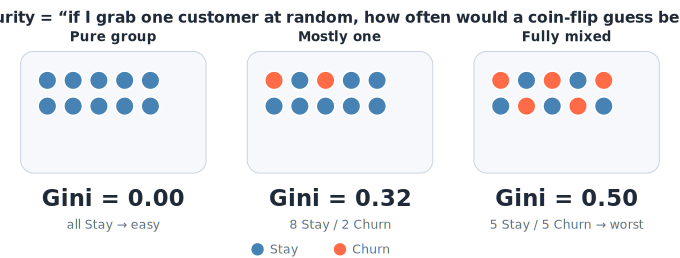

</div>


Formally, for classes with proportions $p_i$: $\;\text{Gini} = 1 - \sum_i p_i^2$. A split is
**good** when its child groups have *lower* Gini than the parent i.e. it sorts churners away from
stayers. At every node the tree tries each feature and threshold and keeps the split that drops
impurity the most.

In [14]:
dt = DecisionTreeClassifier(class_weight="balanced", random_state=RANDOM_STATE)
dt.fit(X_train, y_train)
evaluate("Decision Tree (unconstrained)", dt)

  Decision Tree (unconstrained)
  metric         train    test
  Accuracy       0.998   0.736
  Precision      0.993   0.503
  Recall         0.999   0.497
  F1 (Churn)     0.996   0.500
  F1 gap                 0.496


,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: dict, list of dict or ""balanced"", default=NoneWeights associated with classes in the form ``{class_label: weight}``.If None, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_f

### Another way to score a mix: *Entropy*

Gini isn't the only way to measure how mixed a group is. **Entropy** comes from information theory
and asks a slightly different question about the same bag of marbles:

> *"How surprised will I be, on average, when I find out the label of a customer I pull out?"*

A bag that is **all one colour** → no surprise at all → **Entropy = 0** (perfectly pure).

A **50 / 50** bag → maximum uncertainty, a true toss-up → **Entropy = 1** (the worst case for two classes).

Formally, for classes with proportions $p_i$:

$$\text{Entropy} = -\sum_i p_i \log_2 p_i$$

(with the convention $0 \cdot \log_2 0 = 0$, so a missing class adds nothing). Entropy is measured in *bits*:
it is the average number of yes/no questions you need to pin down a customer's label.

**The same three bags, scored both ways:**

| Bag | Mix | Gini | Entropy |
|-----|-----|------|---------|
| Pure group  | 10 Stay / 0 Churn | 0.00 | 0.00 |
| Mostly one  | 8 Stay / 2 Churn  | 0.32 | 0.72 |
| Fully mixed | 5 Stay / 5 Churn  | 0.50 | 1.00 |

Worked example for the "Mostly one" bag:

$$-(0.8 \log_2 0.8 + 0.2 \log_2 0.2) = -(0.8 \times -0.322 + 0.2 \times -2.322) = 0.258 + 0.464 \approx 0.72$$

**Information gain.** A tree using entropy picks the split with the biggest **information gain**.
That is the parent's entropy minus the *weighted average* entropy of its children (each child is
weighted by its share of the customers):

$$\text{Gain} = H(\text{parent}) - \sum_{\text{child}} \frac{n_{\text{child}}}{n_{\text{parent}}}\, H(\text{child})$$

For example, our full training set is about 26.5% churners, so the root node starts at
$H \approx 0.83$ bits (Gini $\approx 0.39$). Every split tries to bring that number down.

**Gini or entropy, does it matter?** Rarely. Both are 0 for a pure group, peak at a 50/50 mix, and
almost always pick the same split. Entropy punishes small amounts of mixing a little more (0.72 vs
0.32 relative to their maximums of 1 and 0.5). Gini skips the logarithm, so it is slightly faster
to compute, which is why sklearn uses it by default. To try entropy, pass
`DecisionTreeClassifier(criterion="entropy")`.

In [15]:
dt_entropy = DecisionTreeClassifier(criterion = "entropy", class_weight="balanced", random_state=RANDOM_STATE)
dt_entropy.fit(X_train, y_train)
evaluate("Decision Tree (unconstrained)", dt_entropy)

  Decision Tree (unconstrained)
  metric         train    test
  Accuracy       0.998   0.730
  Precision      0.993   0.491
  Recall         0.999   0.484
  F1 (Churn)     0.996   0.487
  F1 gap                 0.509


,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'entropy'
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: dict, list of dict or ""balanced"", default=NoneWeights associated with classes in the form ``{class_label: weight}``.If None, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(ma

## Why `class_weight="balanced"`?

Look at the **"Mostly one"** group above: 8 Stay, 2 Churn, Gini = 0.32.

A tree trained on data like this has an easy shortcut just keep predicting
**Stay** and it's right 80% of the time. The 2 Churn customers barely move the
impurity, so the tree has little incentive to work hard to separate them. But
those churners are usually the whole reason we built the model.

`class_weight="balanced"` fixes this by making the **rare class count for more**.

### What it actually computes

sklearn sets each class weight inversely proportional to how often it appears:

$$w_c = \frac{n_{\text{samples}}}{n_{\text{classes}} \times n_c}$$

For our 8-Stay / 2-Churn node (10 samples, 2 classes):

| Class | Count | Weight $w_c$ | Effective count |
|-------|-------|--------------|-----------------|
| Stay  | 8     | 10 / (2×8) = **0.625** | 8 × 0.625 = **5** |
| Churn | 2     | 10 / (2×2) = **2.50**  | 2 × 2.50 = **5** |

Each Churn example now carries **4× the weight** of a Stay example.

### The connection to Gini

The tree computes impurity from these *weighted* counts, not the raw ones.
So after balancing, the node effectively looks like **5 Stay / 5 Churn**:

$$\text{Gini} = 1 - (0.5^2 + 0.5^2) = 0.50$$



To *see* what a tree does, here are the top few levels of a shallow tree (full depth would be
unreadable). Each box is a yes/no question; colour shows which class dominates the customers that
land there.

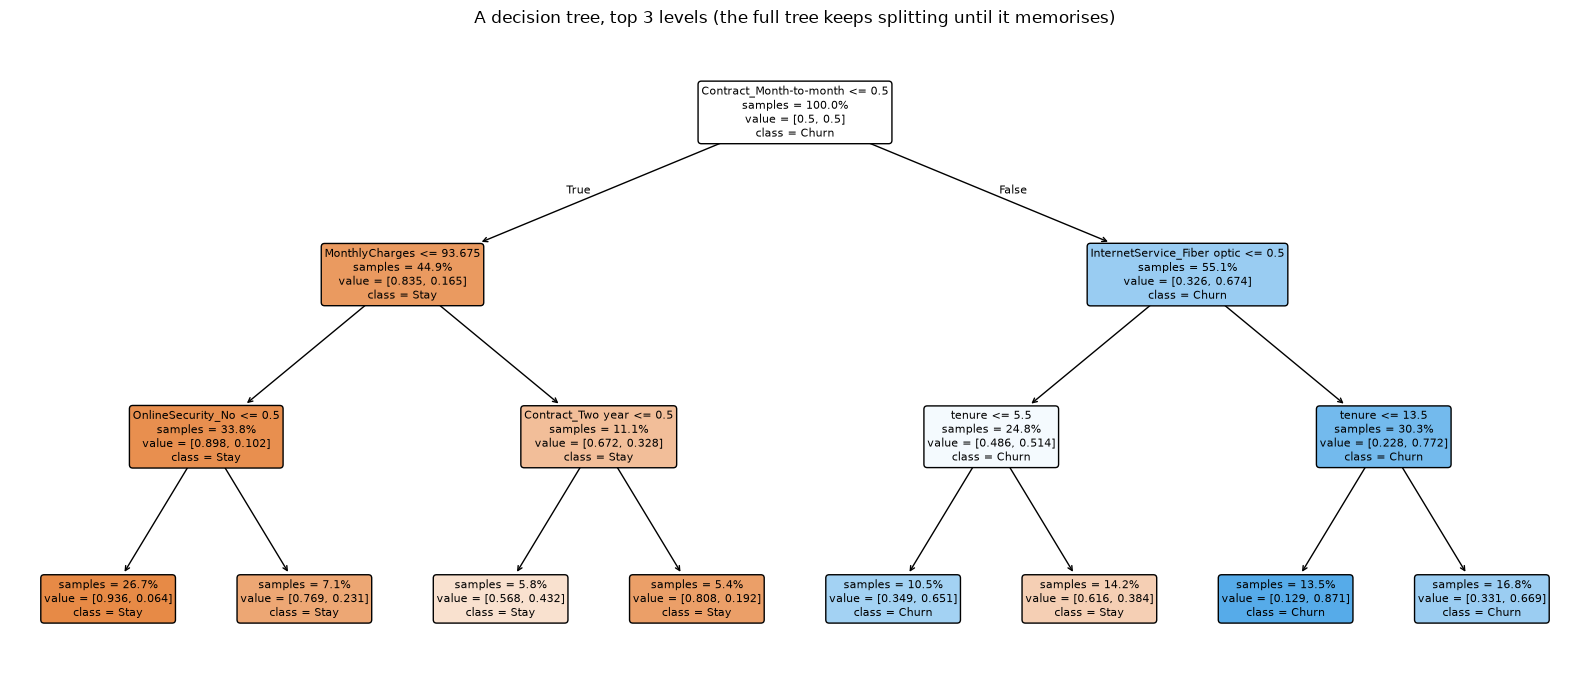

In [16]:
demo_tree = DecisionTreeClassifier(class_weight="balanced", max_depth = 3, random_state=RANDOM_STATE).fit(X_train, y_train)
plt.figure(figsize=(16, 7))
plot_tree(demo_tree, feature_names=feature_names, class_names=["Stay", "Churn"],
          filled=True, rounded=True, fontsize=8, impurity=False, proportion=True)
plt.title("A decision tree, top 3 levels (the full tree keeps splitting until it memorises)")
plt.tight_layout()
plt.show()

## 4: Bagging — Averaging Away the Variance

**How it works.** *Bagging* (Bootstrap Aggregating) draws many bootstrap samples new training
sets of the same size, sampled **with replacement** fits an independent tree on each, and
**averages their votes**. Each tree still overfits its own sample, but their mistakes are only
partly correlated, so averaging cancels much of the noise.

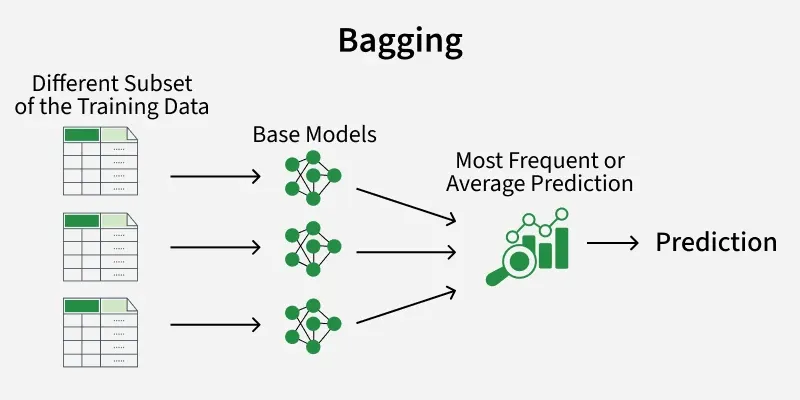







In [17]:
bag = BaggingClassifier(
    estimator=DecisionTreeClassifier(min_samples_split=10, class_weight="balanced", random_state=RANDOM_STATE),
    n_estimators=200,
    max_samples=0.7,
    bootstrap=True,
    random_state=RANDOM_STATE,
)
bag.fit(X_train, y_train)
evaluate("Bagging (200 trees)", bag)

  Bagging (200 trees)
  metric         train    test
  Accuracy       0.921   0.781
  Precision      0.827   0.583
  Recall         0.888   0.618
  F1 (Churn)     0.857   0.600
  F1 gap                 0.257


,"estimator estimator: object, default=NoneThe base estimator to fit on random subsets of the dataset.If None, then the base estimator is a:class:`~sklearn.tree.DecisionTreeClassifier`... versionadded:: 1.2 `base_estimator` was renamed to `estimator`.",DecisionTreeC...ndom_state=42)
,"n_estimators n_estimators: int, default=10The number of base estimators in the ensemble.",200
,"max_samples max_samples: int or float, default=NoneThe number of samples to draw from X to train each base estimator (withreplacement by default, see `bootstrap` for more details).- If None, then draw `X.shape[0]` samples irrespective of `sample_weight`.- If int, then draw `max_samples` samples.- If float, then draw `max_samples * X.shape[0]` unweighted samples or `max_samples * sample_weight.sum()` weighted samples.",0.7
,"random_state random_state: int, RandomState instance or None, default=NoneControls the random resampling of the original dataset(sample wise and feature wise).If the base estimator accepts a `random_state` attribute, a differentseed is generated for each instance in the ensemble.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"max_features max_features: int or float, default=1.0The number of features to draw from X to train each base estimator (without replacement by default, see `bootstrap_features` for moredetails).- If int, then draw `max_features` features.- If float, then draw `max(1, int(max_features * n_features_in_))` features.",1.0
,"bootstrap bootstrap: bool, default=TrueWhether samples are drawn with replacement. If False, sampling withoutreplacement is performed. If fitting with `sample_weight`, it isstrongly recommended to choose True, as only drawing with replacementwill ensure the expected frequency semantics of `sample_weight`.",True
,"bootstrap_features bootstrap_features: bool, default=FalseWhether features are drawn with replacement.",False
,"oob_score oob_score: bool, default=FalseWhether to use out-of-bag samples to estimatethe generalization error. Only available if bootstrap=True.",False
,"warm_start warm_start: bool, default=FalseWhen set to True, reuse the solution of the previous call to fitand add more estimators to the ensemble, otherwise, just fita whole new ensemble. See :term:`the Glossary <warm_start>`... versionadded:: 0.17 *warm_start* constructor parameter.",False
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel for both :meth:`fit` and:meth:`predict`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"verbose verbose: int, default=0Controls the verbosity when fitting and predicting.",0


### Random Forest — bagging with decorrelated trees

**How it works.** A *Random Forest* is bagging plus one extra idea: at **each split**, a tree may
only consider a **random subset of the features** (often about $\sqrt{p}$ of them). This stops
every tree from leaning on the same one or two dominant predictors here, contract type and tenure so the trees **disagree more**. When their predictions are combined, these less-correlated errors can cancel out, making the ensemble more robust than using highly similar trees.

In [18]:
rf = RandomForestClassifier(
    n_estimators=200,
    class_weight="balanced",
    min_samples_split=10,
    random_state=RANDOM_STATE,
)
rf.fit(X_train, y_train)
evaluate("Random Forest", rf)

  Random Forest
  metric         train    test
  Accuracy       0.881   0.763
  Precision      0.706   0.539
  Recall         0.946   0.733
  F1 (Churn)     0.809   0.621
  F1 gap                 0.187


,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",10
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: {""balanced"", ""balanced_subsample""}, dict or list of dicts, default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``The ""balanced_subsample"" mode is the same as ""balanced"" except thatweights are computed based on the bootstrap sample for every treegrown.For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1

## Summary

A single unconstrained tree **memorised** the training data near perfect train F1, weak test F1
because of its **high variance**.

**Bagging** (Bagging, Random Forest) trains many trees **in parallel** on bootstrap samples and
  **averages** them. This attacks **variance**: train F1 drops off its ceiling, test F1 rises, and
  the train/test gap collapses. Random Forest decorrelates the trees further with random feature
  subsets.


| Family | Builds trees… | Mainly reduces… | Watch out for |
|---|---|---|---|
| Bagging | in parallel, then averages | **variance** | won't fix a biased weak learner |

